# Grover con Cirq: ricerca di 101 con 3 qubit
Costruisco il circuito un passo alla volta e stampo ogni **momento**: un gruppo di porte applicate a qubit distinti nello stesso passo del circuito. Uso un simulatore ideale locale, senza account, con **3 qubit di ricerca e un'ancilla** (4 qubit totali).

Gli stati sono scritti nell'ordine **|q2 q1 q0>**. Imposto esplicitamente questo ordine nella simulazione e nella misura.

Ci sono 8 stati e una sola soluzione. Con due iterazioni la probabilità teorica di ottenere `101` è **94,53125%**: non è garantito ottenerlo in ogni singola misura.

L'ancilla viene preparata in $|-\rangle=(|0\rangle-|1\rangle)/\sqrt{2}$ e riutilizzata in entrambe le iterazioni.

## 1. Preparazione
Se Cirq non è installato nel kernel selezionato, eseguire `%pip install cirq-core` in una cella e poi riavviare il kernel. `cirq-core` contiene tutto quello che serve per questo esperimento.

In [18]:
import cirq
import numpy as np
import matplotlib.pyplot as plt

q0, q1, q2 = cirq.LineQubit.range(3)
ancilla = cirq.NamedQubit("anc")
ordine = [q2, q1, q0]  # ordine dei bit nelle stringhe e nel vettore di stato
ordine_completo = ordine + [ancilla]  # |q2 q1 q0 anc>
soluzione = "101"
indice_soluzione = int(soluzione, 2)
stati = [f"{i:03b}" for i in range(8)]
iterazioni = 2
simulatore = cirq.Simulator(dtype=np.complex128, seed=42)
print("Versione Cirq:", cirq.__version__)
print("Qubit di ricerca: 3; ancilla: 1; soluzione:", soluzione)

Versione Cirq: 1.7.0
Qubit di ricerca: 3; ancilla: 1; soluzione: 101


## 2. Costruzione con ancilla e phase kickback
Preparo l'ancilla con X e poi H: da |0> passa a |1> e infine a |->.

Uso una **X con tre controlli**, uno per ogni qubit di ricerca, e l'ancilla come target. Quando tutti i controlli valgono 1, vale $X|-\rangle=-|-\rangle$: l'ancilla resta nello stesso stato e il termine corrispondente del registro di ricerca cambia segno (phase kickback).

Per marcare `101`, applico X al qubit centrale prima e dopo la porta controllata. Nel diffusore uso H, X, la stessa X a tre controlli, X, H: le H e le X del diffusore agiscono solo sui qubit di ricerca. Il diffusore ottenuto differisce da quello usuale per una fase globale, irrilevante per le misure.

Tengo i momenti separati per seguire ogni passaggio. Non servono altre ancilla nel circuito logico.

In [19]:
circuito = cirq.Circuit()
descrizioni = []
fine_fasi = {}

def aggiungi_momento(testo, porte):
    circuito.append(cirq.Moment(porte))
    descrizioni.append(testo)
    print(f"\nMomento {len(circuito)}: {testo}")
    print(cirq.Circuit(circuito[-1]))

aggiungi_momento("Ancilla: da |0> a |1>", [cirq.X(ancilla)])
aggiungi_momento("Ancilla: da |1> a |->", [cirq.H(ancilla)])

aggiungi_momento("Sovrapposizione iniziale", [cirq.H(q) for q in ordine])
fine_fasi[len(circuito)] = "Sovrapposizione"

for k in range(1, iterazioni + 1):
    print(f"\n--- Iterazione {k} ---")
    aggiungi_momento("Oracolo: X sul bit centrale", [cirq.X(q1)])
    aggiungi_momento("Oracolo: X a tre controlli, phase kickback", [cirq.X(ancilla).controlled_by(q0, q1, q2)])
    aggiungi_momento("Oracolo: ripristino del bit centrale", [cirq.X(q1)])
    fine_fasi[len(circuito)] = f"Oracolo {k}"

    aggiungi_momento("Diffusore: H", [cirq.H(q) for q in ordine])
    aggiungi_momento("Diffusore: X", [cirq.X(q) for q in ordine])
    aggiungi_momento("Diffusore: X a tre controlli, phase kickback", [cirq.X(ancilla).controlled_by(q0, q1, q2)])
    aggiungi_momento("Diffusore: X", [cirq.X(q) for q in ordine])
    aggiungi_momento("Diffusore: H", [cirq.H(q) for q in ordine])
    fine_fasi[len(circuito)] = f"Diffusore {k}"

print("\nCircuito completo (prima della misura):")
print(circuito)


Momento 1: Ancilla: da |0> a |1>
anc: ───X───

Momento 2: Ancilla: da |1> a |->
anc: ───H───

Momento 3: Sovrapposizione iniziale
0: ───H───

1: ───H───

2: ───H───

--- Iterazione 1 ---

Momento 4: Oracolo: X sul bit centrale
1: ───X───

Momento 5: Oracolo: X a tre controlli, phase kickback
0: ─────@───
        │
1: ─────@───
        │
2: ─────@───
        │
anc: ───X───

Momento 6: Oracolo: ripristino del bit centrale
1: ───X───

Momento 7: Diffusore: H
0: ───H───

1: ───H───

2: ───H───

Momento 8: Diffusore: X
0: ───X───

1: ───X───

2: ───X───

Momento 9: Diffusore: X a tre controlli, phase kickback
0: ─────@───
        │
1: ─────@───
        │
2: ─────@───
        │
anc: ───X───

Momento 10: Diffusore: X
0: ───X───

1: ───X───

2: ───X───

Momento 11: Diffusore: H
0: ───H───

1: ───H───

2: ───H───

--- Iterazione 2 ---

Momento 12: Oracolo: X sul bit centrale
1: ───X───

Momento 13: Oracolo: X a tre controlli, phase kickback
0: ─────@───
        │
1: ─────@───
        │
2: ────

## 3. Stato dopo ogni momento
Ora simulo il circuito e stampo ampiezze e probabilità dopo **ogni momento**. Le ampiezze sono reali in questo esempio.

Il vettore completo contiene 16 ampiezze, nell'ordine |q2 q1 q0 anc>. Per ciascuno degli otto stati di ricerca stampo le due ampiezze associate ad anc=0 e anc=1. La probabilità del solo registro di ricerca si ottiene sommando i loro moduli al quadrato. L'ancilla non viene misurata.

In [20]:
probabilita_fasi = {}
for numero, passo in enumerate(
    simulatore.simulate_moment_steps(circuito, qubit_order=ordine_completo), start=1
):
    ampiezze = passo.state_vector().copy()
    ampiezze = ampiezze.reshape(8, 2)  # righe: ricerca; colonne: ancilla
    probabilita = np.sum(np.abs(ampiezze)**2, axis=1)
    print(f"\nMomento {numero}: {descrizioni[numero - 1]}")
    print("Ricerca   Amp(anc=0)   Amp(anc=1)   Prob. ricerca")
    for stato, coppia, p in zip(stati, ampiezze, probabilita):
        print(f"{stato}       {coppia[0].real:+.5f}      {coppia[1].real:+.5f}       {p:8.3%}")
    if numero >= 2:
        # In |-> le due colonne sono opposte: l'ancilla resta separabile.
        assert np.allclose(ampiezze[:, 0], -ampiezze[:, 1])
    if numero in fine_fasi:
        fase = fine_fasi[numero]
        probabilita_fasi[fase] = probabilita.copy()
        print(f">>> Fine {fase}: P(101) = {probabilita[indice_soluzione]:.5%}")

probabilita_finali = probabilita.copy()


Momento 1: Ancilla: da |0> a |1>
Ricerca   Amp(anc=0)   Amp(anc=1)   Prob. ricerca
000       +0.00000      +1.00000       100.000%
001       +0.00000      +0.00000         0.000%
010       +0.00000      +0.00000         0.000%
011       +0.00000      +0.00000         0.000%
100       +0.00000      +0.00000         0.000%
101       +0.00000      +0.00000         0.000%
110       +0.00000      +0.00000         0.000%
111       +0.00000      +0.00000         0.000%

Momento 2: Ancilla: da |1> a |->
Ricerca   Amp(anc=0)   Amp(anc=1)   Prob. ricerca
000       +0.70711      -0.70711       100.000%
001       +0.00000      -0.00000         0.000%
010       +0.00000      -0.00000         0.000%
011       +0.00000      -0.00000         0.000%
100       +0.00000      -0.00000         0.000%
101       +0.00000      -0.00000         0.000%
110       +0.00000      -0.00000         0.000%
111       +0.00000      -0.00000         0.000%

Momento 3: Sovrapposizione iniziale
Ricerca   Amp(anc=0)   Amp(

## 4. Amplificazione della soluzione
Confronto le probabilità dopo la preparazione e dopo ciascun diffusore. Dopo la prima iterazione P(101) è 78,125%; dopo la seconda sale al 94,53125%.

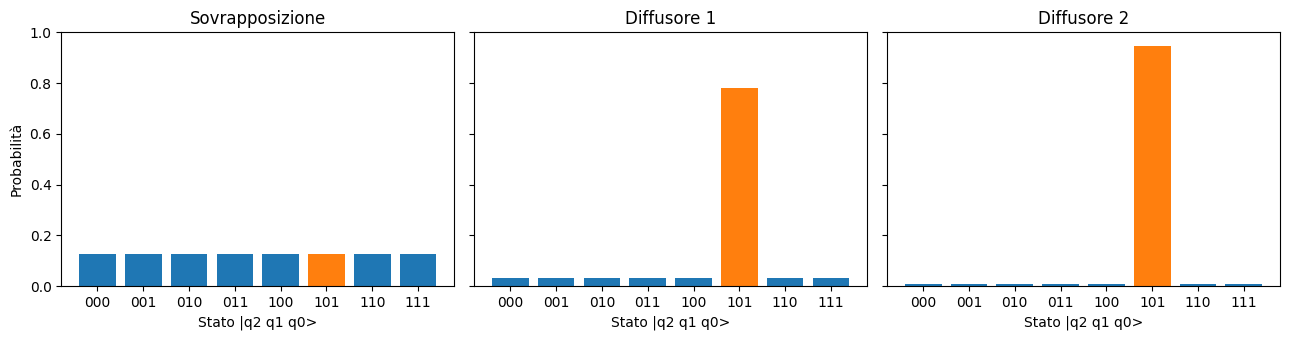

Probabilità teorica: 94.53125%
Probabilità dal vettore di stato: 94.53125%


In [21]:
fig, assi = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for asse, fase in zip(assi, ["Sovrapposizione", "Diffusore 1", "Diffusore 2"]):
    colori = ["tab:orange" if s == soluzione else "tab:blue" for s in stati]
    asse.bar(stati, probabilita_fasi[fase], color=colori)
    asse.set(title=fase, xlabel="Stato |q2 q1 q0>", ylim=(0, 1))
assi[0].set_ylabel("Probabilità")
plt.tight_layout()
plt.show()

theta = np.arcsin(np.sqrt(1 / 8))
p_teorica = np.sin((2 * iterazioni + 1) * theta)**2
print(f"Probabilità teorica: {p_teorica:.5%}")
print(f"Probabilità dal vettore di stato: {probabilita_finali[indice_soluzione]:.5%}")
assert np.isclose(probabilita_finali[indice_soluzione], p_teorica)

## 5. Misure ripetute
Aggiungo la misura solo alla fine ed eseguo 1024 ripetizioni. La frequenza osservata può essere leggermente diversa dalla probabilità teorica a causa del campionamento. Il seme casuale rende riproducibile l'esperimento.

Misuro soltanto q2, q1 e q0: il risultato resta una stringa di tre bit, senza il bit dell'ancilla.

Circuito con misura finale:
0: ─────────────H───────@───────H───X───@───X───H───────@───────H───X───@───X───H───M────────────────
                        │               │               │               │           │
1: ─────────────H───X───@───X───H───X───@───X───H───X───@───X───H───X───@───X───H───M────────────────
                        │               │               │               │           │
2: ─────────────H───────@───────H───X───@───X───H───────@───────H───X───@───X───H───M('risultato')───
                        │               │               │               │
anc: ───X───H───────────X───────────────X───────────────X───────────────X────────────────────────────

Stato   Conteggi   Frequenza   Probabilità ideale
000        4        0.39%         0.78%
001        9        0.88%         0.78%
010        9        0.88%         0.78%
011       13        1.27%         0.78%
100       10        0.98%         0.78%
101      964       94.14%        94.53%
110       11        1.07%  

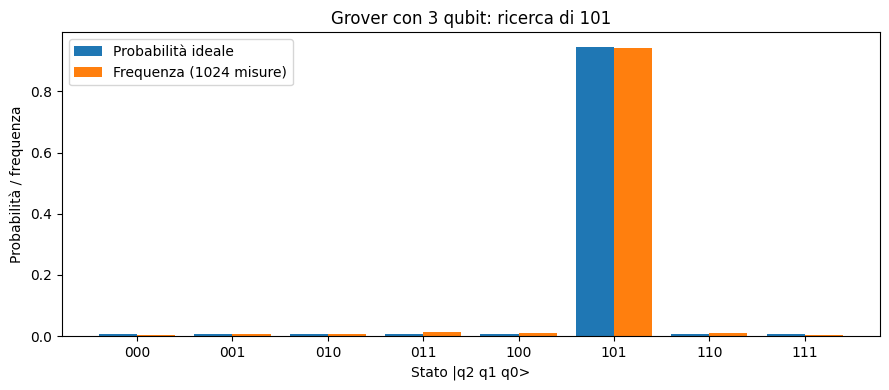


Soluzione cercata: 101; frequenza osservata: 94.14%


In [22]:
circuito_misurato = circuito.copy()
circuito_misurato.append(cirq.measure(*ordine, key="risultato"))
print("Circuito con misura finale:")
print(circuito_misurato)

shots = 1024
risultato = simulatore.run(circuito_misurato, repetitions=shots)
conteggi = risultato.histogram(key="risultato")
frequenze = [conteggi.get(i, 0) / shots for i in range(8)]
print("\nStato   Conteggi   Frequenza   Probabilità ideale")
for i, stato in enumerate(stati):
    print(f"{stato}     {conteggi.get(i, 0):4d}      {frequenze[i]:7.2%}       {probabilita_finali[i]:7.2%}")

x = np.arange(8)
plt.figure(figsize=(9, 4))
plt.bar(x - 0.2, probabilita_finali, width=0.4, label="Probabilità ideale")
plt.bar(x + 0.2, frequenze, width=0.4, label=f"Frequenza ({shots} misure)")
plt.xticks(x, stati)
plt.xlabel("Stato |q2 q1 q0>")
plt.ylabel("Probabilità / frequenza")
plt.title("Grover con 3 qubit: ricerca di 101")
plt.legend()
plt.tight_layout()
plt.show()
print(f"\nSoluzione cercata: {soluzione}; frequenza osservata: {frequenze[indice_soluzione]:.2%}")

## Osservazioni
- Le H iniziali rendono equiprobabili gli otto stati (12,5% ciascuno).
- L'oracolo completo cambia una fase, senza aumentare da solo la probabilità della soluzione.
- Due iterazioni amplificano `101` fino al 94,53125%, usando tre qubit di ricerca e un'ancilla in |->.
- Il simulatore permette di seguire le ampiezze; le misure finali restituiscono invece singole stringhe di bit.

Riferimento: [documentazione ufficiale Cirq sulla simulazione e sui momenti](https://quantumai.google/cirq/simulate/simulation).